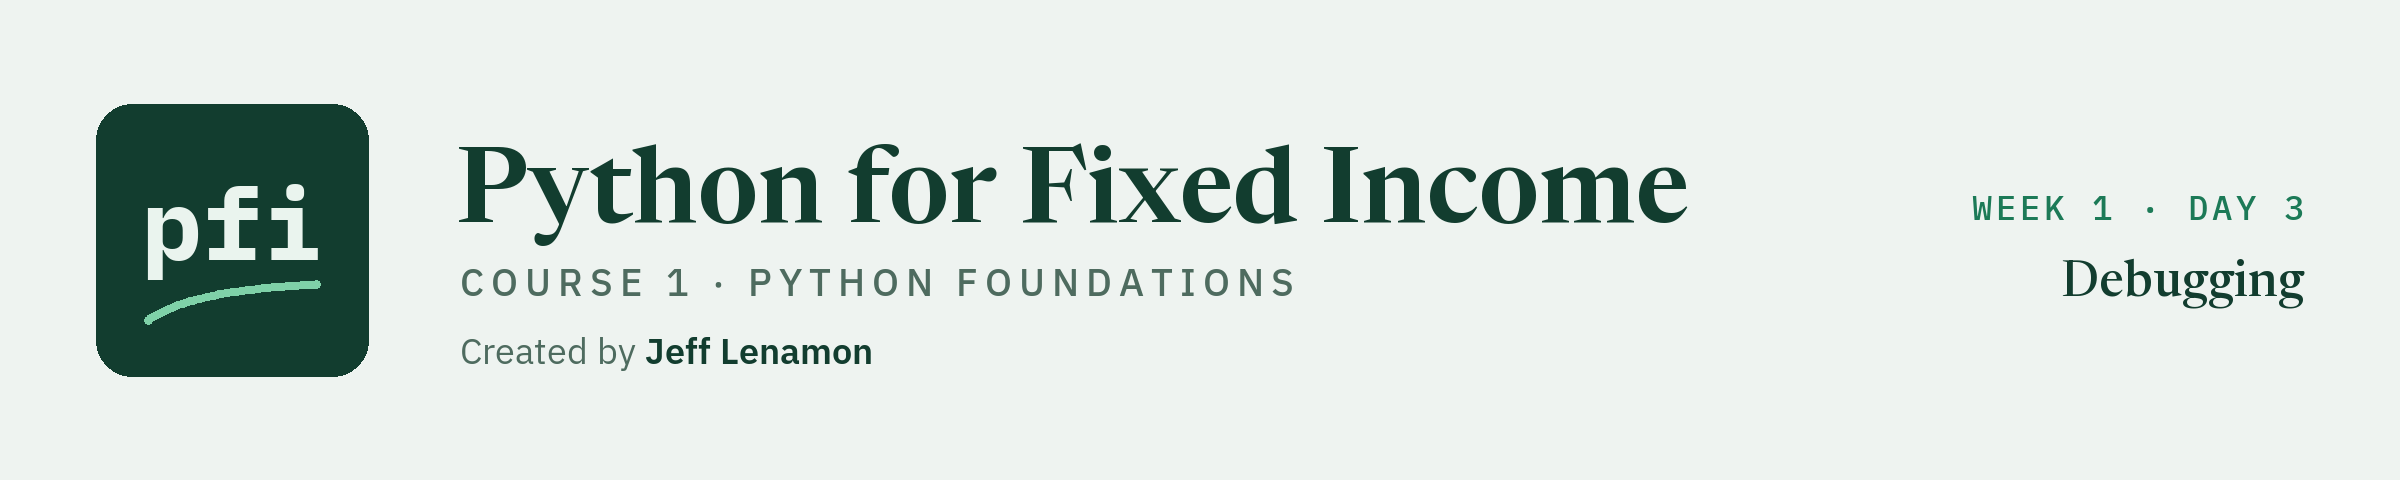

# Debugging

Week 1. Finding and fixing the mistakes in code, using broken calculations from a bond desk.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day3/03_debugging.ipynb)

## Before you start: install the libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


Everyone who writes code makes mistakes, on the first day and after twenty years.

A mistake in code is called a **bug**, and finding and fixing it is called **debugging**.

Python helps: when it cannot run something, it stops and says what went wrong and where.

Stopping with an error is called **raising** the error.

A new analyst has joined the credit desk and written some code for the desk's four bonds.

Every piece of it has a bug.

In this notebook we find and fix each one.

The red error blocks you will see are there on purpose.

For every bug we follow the same four steps:

1. Run the code and let it fail.
2. Read what Python says, starting from the last line, as on Day 0.
3. Work out the cause.
4. Fix it and run it again.

The four bonds are the ones from the earlier notebooks.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Face held</th></tr>
<tr><td align="left">QVNE</td><td align="left">5.25</td><td align="left">2033</td><td align="left">98.50</td><td align="left">BBB</td><td align="left">1,500,000</td></tr>
<tr><td align="left">DNMR</td><td align="left">6.125</td><td align="left">2034</td><td align="left">103.25</td><td align="left">BB+</td><td align="left">500,000</td></tr>
<tr><td align="left">PLWK</td><td align="left">4.75</td><td align="left">2031</td><td align="left">95.00</td><td align="left">A-</td><td align="left">750,000</td></tr>
<tr><td align="left">HLVF</td><td align="left">7.50</td><td align="left">2032</td><td align="left">101.00</td><td align="left">B+</td><td align="left">250,000</td></tr>
</table>
<br clear="left">

In [2]:
# the desk's data, as lists
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
face_list = [1500000, 500000, 750000, 250000]

## 3.1 Reading a Traceback

Q. The analyst wants to print the coupon of QVNE. Run the code.

In [3]:
# store the coupon of QVNE
coupon = 5.25
# print it
print('The coupon is', cupon)

NameError: name 'cupon' is not defined

The red block is the **traceback** you met on Day 1: Python's report of what went wrong.

Read it from the bottom up:

* **The last line names the error.** Here it is a `NameError`, and the message says the name 'cupon' is not defined.
* **The arrow marks the line.** `---->` points at the line where Python stopped.
* **The top says which cell.** The number in `Cell In[...]` matches the number beside the cell.

The cause: the variable was stored as `coupon` and then spelled `cupon`.

To Python those are two different names.

Ask three questions of every traceback: **what type of error, what does the message say, and which line.**

In [4]:
# store the coupon of QVNE
coupon = 5.25
# print it, with the name spelled correctly
print('The coupon is', coupon)

The coupon is 5.25


> STORY: On September 9, 1947, engineers working on Harvard's Mark II computer found a moth inside the machine. Someone taped it into the log book with a note calling it the first actual case of a bug being found. The joke only works because engineers already called faults "bugs": Thomas Edison used the word that way in a letter in 1878. The log book, moth included, is in the Smithsonian's National Museum of American History. The story is often told about Grace Hopper, who worked on the Mark II, but the museum notes the log book was probably not hers.
>
> Source: https://daily.jstor.org/the-bug-in-the-computer-bug-story/ and the museum's object record at https://americanhistory.si.edu/collections/object/nmah_334663

## 3.2 Syntax Errors

**Syntax** is the grammar of the language.

A syntax error means Python could not even read the code, so nothing in the cell runs at all.

Q. The analyst wants to print every ticker. Run the code.

In [5]:
for ticker in ticker_list
    print(ticker)

SyntaxError: expected ':' (627221158.py, line 1)

A `SyntaxError`.

The message says a colon was expected, and a small `^` points at the exact spot.

A `for` line must end with a colon.

So must `if`, `elif`, `else`, `while`, `def`, and `with`.

In [6]:
# the colon at the end of the for line was missing
for ticker in ticker_list:
    print(ticker)

QVNE
DNMR
PLWK
HLVF


Q. The analyst wants to check whether QVNE trades at par. Run the code.

In [7]:
price = 98.5

if price = 100:
    print('QVNE trades at par')
else:
    print('QVNE does not trade at par')

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (4219805903.py, line 3)

Another `SyntaxError`, and this time Python suggests the fix.

A single `=` stores a value.

A double `==` asks whether two values are equal.

An `if` needs a question, so it needs `==`.

The `:=` in the message is a rarer tool that this course does not use.

In [8]:
price = 98.5

# == compares, = stores
if price == 100:
    print('QVNE trades at par')
else:
    print('QVNE does not trade at par')

QVNE does not trade at par


Q. The analyst wants to add a fifth coupon to the list. Run the code.

In [9]:
new_coupon_list = [5.25, 6.125, 4.75, 7.5, 6.0
print(new_coupon_list)

SyntaxError: '[' was never closed (424841642.py, line 1)

The message says the `[` was never closed.

Every opening bracket, parenthesis, and quote needs its partner.

Here Python points at the opening bracket that was never closed.

With other mistakes it can stop on the line after the real error.

If the marked line looks fine, check the line above it.

In [10]:
# the closing bracket was missing
new_coupon_list = [5.25, 6.125, 4.75, 7.5, 6.0]
print(new_coupon_list)

[5.25, 6.125, 4.75, 7.5, 6.0]


Q. The analyst wants to print each price. Run the code.

In [11]:
for price in price_list:
print(price)

IndentationError: expected an indented block after 'for' statement on line 1 (2214392936.py, line 2)

An `IndentationError`.

The line after a colon must be indented, because the indentation is how Python knows what belongs inside the loop.

In [12]:
# the line inside the loop must be indented
for price in price_list:
    print(price)

98.5
103.25
95.0
101.0


**Excel side by side.** Excel refuses in the same way.

Type `=1+` in a cell and press Enter, and Excel shows a message and will not take the formula until it is fixed.

Nothing is calculated, just as nothing in these cells ran.

## 3.3 Name and Type Errors

From here on the code is valid Python, so it starts running.

The error appears only when Python reaches the line it cannot carry out.

Q. The analyst wants to store QVNE as a dictionary. Run the code.

In [13]:
bond = {Ticker: 'QVNE', 'Coupon': 5.25, 'Price': 98.5}
print(bond)

NameError: name 'Ticker' is not defined

A `NameError`: the name 'Ticker' is not defined.

Without quotes, Python reads `Ticker` as a variable name and goes looking for a variable that does not exist.

A dictionary key that is text needs quotes.

In [14]:
# the key 'Ticker' needs quotes, like the other keys
bond = {'Ticker': 'QVNE', 'Coupon': 5.25, 'Price': 98.5}
print(bond)

{'Ticker': 'QVNE', 'Coupon': 5.25, 'Price': 98.5}


Q. The analyst wants to print a one-line description of QVNE. Run the code.

In [15]:
description = 'QVNE ' + 5.25 + '% of ' + 2033
print(description)

TypeError: can only concatenate str (not "float") to str

The `TypeError` from Day 1: Python can only join a string to another string.

A type error means the operation is fine but the data type is wrong for it.

The cure is the one from Day 1, `str()`.

In [16]:
# turn each number into a string, then join
description = 'QVNE ' + str(5.25) + '% of ' + str(2033)
print(description)

QVNE 5.25% of 2033


Q. The face held of QVNE arrives from a file as text. The analyst wants the annual coupon income. Run the code.

In [17]:
# the face amount as it arrived from the file
face = '1500000'
coupon = 5.25

income = face * coupon / 100
print('The annual coupon income is', income)

TypeError: can't multiply sequence by non-int of type 'float'

Another `TypeError`, with a stranger message: can't multiply sequence by non-int of type 'float'.

A **sequence** is a set of items in a row, and a string is a row of characters.

`non-int` means not a whole number.

So Python is saying it cannot multiply text by a decimal number.

The clue is in the first line of the cell: the face amount is in quotes, so it is a string.

When a message makes no sense, check the type of each variable with `type()`, as on Day 1.

In [18]:
# check the types
print(type(face))
print(type(coupon))

<class 'str'>
<class 'float'>


Q. The message said non-int. So what happens when text is multiplied by a whole number?

In [19]:
# face is still the text '1500000'
print(face * 2)

15000001500000


The result is 15000001500000: the text written twice.

There is no error and no arithmetic.

Times a whole number, a string repeats, which is why Python only objected to the decimal.

`=REPT("1500000",2)` does the same in Excel, and there you have to ask for it.

The fix is to turn the text into a number.

In [20]:
# convert the text to a number before using it
face = int('1500000')
coupon = 5.25

income = face * coupon / 100
print('The annual coupon income is', income)

The annual coupon income is 78750.0


**Excel side by side.** Excel is more forgiving here.

If A1 holds 1500000 stored as text, `=A1*5.25/100` still returns 78750, because Excel's arithmetic converts text that looks like a number.

Python never converts for you.

Q. The analyst wants to round the QVNE price down to a whole number of points. Python's `math` module has a function for that: `math.floor` rounds down to the whole number below. Run the code.

In [21]:
whole_points = math.floor(98.5)
print(whole_points)

NameError: name 'math' is not defined

A `NameError` again: the name 'math' is not defined.

The message looks like the typo in section 3.1, but this time the spelling is right.

As on Day 2, a module has to be loaded with `import` before its name can be used.

Only the built-in tools, such as `print`, `len`, and `sum`, are ready from the start.

In [22]:
# load the math module first, then use it
import math

whole_points = math.floor(98.5)
print(whole_points)

98


**Excel side by side.** `=INT(98.5)` does the same job as `math.floor(98.5)`.

Both round down and return 98.

Q. The analyst wants to add a fifth ticker to the end of the list. Run the code.

In [23]:
ticker_list.add('ZXMT')

AttributeError: 'list' object has no attribute 'add'

An `AttributeError`: 'list' object has no attribute 'add'.

**Object** is Python's word for any value it is holding: a list, a string, a number.

An **attribute** is anything reached from an object with a dot.

The methods from Day 1 are attributes.

A list has `append`, `pop`, and `sort`, but nothing called `add`.

Python names the type it found, `list`, so the clue is in the message.

Q. When the name of a method is in doubt, how do we find it?

In [24]:
# dir() lists the names an object carries. startswith() is endswith() for the other end of a string
# names that begin with _ are for Python's own use, so we leave them out
print([name for name in dir(ticker_list) if not name.startswith('_')])

['append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']


There it is: `append`, and no `add`.

Q. What does `append` do?

In [25]:
# help() from Day 1 works on a method too, written with no brackets after its name
help(ticker_list.append)

Help on built-in function append:

append(object, /) method of builtins.list instance
    Append object to the end of the list.



The last line is the docstring: it adds an item to the end of the list.

Pass over the `/`, which this course does not need.

Q. Add the ticker with `append`, then take it off again so that the desk keeps its four bonds.

In [26]:
ticker_list.append('ZXMT')
print(ticker_list)

# pop() from Day 1 removes the last item
ticker_list.pop()
print(ticker_list)

['QVNE', 'DNMR', 'PLWK', 'HLVF', 'ZXMT']
['QVNE', 'DNMR', 'PLWK', 'HLVF']


## 3.4 Index and Key Errors

Q. The analyst wants to print the ticker of each of the four bonds. Run the code.

In [27]:
for i in range(1, 5):
    print(ticker_list[i])

DNMR
PLWK
HLVF


IndexError: list index out of range

An `IndexError`: list index out of range.

Notice that three tickers printed before the error.

The code ran until it hit the problem.

Notice also that QVNE is missing.

The list has four items at indexes 0, 1, 2, and 3.

`range(1, 5)` produces 1, 2, 3, and 4, so the loop skipped index 0 and then asked for index 4, which does not exist.

Counting from 1 when Python counts from 0 is one of the most common bugs there is.

In [28]:
# range(4) produces 0, 1, 2, 3
for i in range(4):
    print(ticker_list[i])

QVNE
DNMR
PLWK
HLVF


Better still, loop over the list itself.

With no index, there is nothing to get wrong.

In [29]:
for ticker in ticker_list:
    print(ticker)

QVNE
DNMR
PLWK
HLVF


**Excel side by side.** Excel counts from 1: `=INDEX(A1:A4,1)` returns the first item.

That is why the habit is so easy to bring to Python.

And `=INDEX(A1:A4,5)` on a four-cell range returns `#REF!`, which is Excel's `IndexError`.

Q. The analyst wants to print the coupon stored in the dictionary. Run the code.

In [30]:
bond = {'Ticker': 'QVNE', 'Coupon': 5.25, 'Price': 98.5}
print(bond['coupon'])

KeyError: 'coupon'

A `KeyError`.

The message is just the key that Python could not find: 'coupon'.

The key in the dictionary is 'Coupon', with a capital letter.

Keys must match exactly, including upper and lower case.

To see which keys a dictionary has, print `bond.keys()`.

In [31]:
# list the keys to see how they are spelled
print(bond.keys())
# use the key exactly as it is stored
print(bond['Coupon'])

dict_keys(['Ticker', 'Coupon', 'Price'])
5.25


**Excel side by side.** Excel's lookups ignore case.

With the labels in A1:A3 and the values in B1:B3, `=XLOOKUP("coupon",A1:A3,B1:B3)` finds a label typed as Coupon.

A dictionary does not, so this is a bug Excel would never show you.

## 3.5 Value and Zero Errors

Q. A broker sends the QVNE coupon as the text '5.25%'. The analyst wants it as a number. Run the code.

In [32]:
coupon_text = '5.25%'
coupon = float(coupon_text)
print(coupon)

ValueError: could not convert string to float: '5.25%'

A `ValueError`: could not convert string to float.

A value error means the type is right but the content is not.

`float()` does accept a string, just not one with a percent sign in it.

In [33]:
coupon_text = '5.25%'
# replace the percent sign with nothing, then convert
coupon = float(coupon_text.replace('%', ''))
print(coupon)

5.25


**Excel side by side.** `=VALUE("5.25%")` works in Excel and returns 0.0525, because Excel reads the percent sign and divides by 100.

`float()` does not read it.

Our fix gives 5.25, in percent, which is how the desk's coupons are stored.

Q. The analyst wants the current yield of each bond, which is the coupon divided by the price. Today's price feed has a problem: one price came through as 0. Run the code.

In [34]:
# today's prices, with a bad value for PLWK
feed_price_list = [98.5, 103.25, 0, 101.0]

for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    print(ticker, round(coupon / price * 100, 2))

QVNE 5.33
DNMR 5.93


ZeroDivisionError: float division by zero

A `ZeroDivisionError`.

Two bonds printed, then the loop reached PLWK and tried to divide by zero.

This time the code is correct.

The data is wrong.

A bond does not have a price of 0, so the right fix is to deal with the bad value, not to change the formula.

In [35]:
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    # skip any bond whose price is not a positive number, and say so
    if price <= 0:
        print(ticker, 'has a bad price:', price)
    else:
        print(ticker, round(coupon / price * 100, 2))

QVNE 5.33
DNMR 5.93
PLWK has a bad price: 0
HLVF 7.43


The loop now finishes, and the bad price is reported instead of hidden.

## 3.6 Errors Inside Functions

When the failing line is inside a function, the traceback gets longer.

It shows the line that called the function, and then the line inside the function that failed.

Q. The analyst wrote a function for current yield and used it in a loop. One price in the feed arrived as text. Run the code.

In [36]:
def current_yield(coupon, price):
    """
    Take the coupon (in percent) and the price (per 100 face)
    and return the current yield in percent.
    """
    return coupon / price * 100

In [37]:
# today's prices, with one that arrived as text
feed_price_list = [98.5, 103.25, '95.0', 101.0]

for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    print(ticker, round(current_yield(coupon, price), 2))

QVNE 5.33
DNMR 5.93


TypeError: unsupported operand type(s) for /: 'float' and 'str'

There are now two arrows.

Read from the bottom as always.

**The last line** says it is a `TypeError`: Python cannot divide a float by a string.

**The lower arrow** is inside the function, on the `return` line.

That is where the division failed.

**The upper arrow** is in our loop, on the line that called `current_yield`.

That is how Python got there.

The function is fine.

It was handed bad data.

The lower arrow shows where the error happened, and the upper arrow shows where the bad value came from.

The fix belongs in the loop.

In [38]:
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    # convert every price to a number before passing it to the function
    price = float(price)
    print(ticker, round(current_yield(coupon, price), 2))

QVNE 5.33
DNMR 5.93
PLWK 5.0
HLVF 7.43


**The errors so far, in one table.** Read the last line of the traceback, find its name here, and check the first thing in the right-hand column.

<table align="left">
<tr><th align="left">Error</th><th align="left">What Python is telling you</th><th align="left">First thing to check</th></tr>
<tr><td align="left"><code>SyntaxError</code>, <code>IndentationError</code></td><td align="left">The code is not written in a form Python can read</td><td align="left">A missing colon, bracket, or quote; a line that is not indented</td></tr>
<tr><td align="left"><code>NameError</code></td><td align="left">A name has not been created</td><td align="left">A spelling mistake, a missing quote, a missing <code>import</code>, a cell not yet run</td></tr>
<tr><td align="left"><code>TypeError</code></td><td align="left">The operation does not work on this type of data</td><td align="left"><code>type()</code> of each variable; text where a number should be</td></tr>
<tr><td align="left"><code>ValueError</code></td><td align="left">The type is right, the content is not</td><td align="left">The text being converted, such as '5.25%'</td></tr>
<tr><td align="left"><code>IndexError</code></td><td align="left">The position is past the end of the list</td><td align="left">The length of the list; <code>range</code> that starts or stops one off</td></tr>
<tr><td align="left"><code>KeyError</code></td><td align="left">The dictionary has no such key</td><td align="left">The keys, with <code>.keys()</code>, spelled and capitalised exactly</td></tr>
<tr><td align="left"><code>AttributeError</code></td><td align="left">This type of object has no such method</td><td align="left">The method name, with <code>dir()</code> or <code>help()</code></td></tr>
<tr><td align="left"><code>ZeroDivisionError</code></td><td align="left">A division by 0</td><td align="left">The data: a bad zero is usually the problem, and not the code</td></tr>
</table>
<br clear="left">

## 3.7 Bugs With No Error

The most dangerous bugs raise no error at all.

The code runs, prints a number, and the number is wrong.

Q. The analyst wants the annual coupon income on the QVNE position: 1,500,000 face with a 5.25 percent coupon. Run the code.

In [39]:
face = 1500000
coupon = 5.25

income = face * coupon
print('The annual coupon income is', income)

The annual coupon income is 7875000.0


No error.

But 7.9 million dollars of coupon on a 1.5 million position cannot be right.

A 5.25 percent coupon should pay a little over 5 percent of the face, so somewhere near 79,000.

The coupon is in percent and was never divided by 100.

Python had no way to know.

The only defense is knowing roughly what the answer should be before you run the code.

In [40]:
face = 1500000
coupon = 5.25

# the coupon is in percent, so divide by 100
income = face * coupon / 100
print('The annual coupon income is', income)

The annual coupon income is 78750.0


Q. The analyst wants the simple average coupon of the four bonds. Run the code.

In [41]:
total = 0
for coupon in coupon_list:
    total = coupon

average_coupon = total / len(coupon_list)
print('The average coupon is', average_coupon)

The average coupon is 1.875


No error again.

But the coupons run from 4.75 to 7.5, so an average of 1.875 is impossible.

An average must lie between the smallest and largest value.

When the cause is not obvious, add a `print()` inside the loop and watch the values change.

This is the simplest debugging tool there is.

In [42]:
total = 0
for coupon in coupon_list:
    total = coupon
    # print the values on every pass through the loop
    print('coupon:', coupon, ' total so far:', total)

coupon: 5.25  total so far: 5.25
coupon: 6.125  total so far: 6.125
coupon: 4.75  total so far: 4.75
coupon: 7.5  total so far: 7.5


The total is not growing.

On each pass it is simply replaced by the latest coupon.

The line should add the coupon to the total.

**Excel side by side.** A `print()` inside a loop does the job of Evaluate Formula on Excel's Formulas tab: both show the working one step at a time.

In [43]:
total = 0
for coupon in coupon_list:
    # add each coupon to the running total
    total = total + coupon

average_coupon = total / len(coupon_list)
print('The average coupon is', average_coupon)

The average coupon is 5.90625


The answer is 5.90625, which sits between 4.75 and 7.5 as it should.

Once the bug is fixed, take the extra `print()` out.

Q. The analyst wants to try a new mark on QVNE without touching the desk's price list. The code makes a second list and changes its first price. Run the code.

In [44]:
# the desk's prices, and what looks like a second list for the what-if
what_if_list = price_list
what_if_list[0] = 99.0

print(f'What-if prices: {what_if_list}')
print(f'Desk prices:    {price_list}')

What-if prices: [99.0, 103.25, 95.0, 101.0]
Desk prices:    [99.0, 103.25, 95.0, 101.0]


No error, and both lists changed.

The desk's QVNE price is now 99.0 as well.

`what_if_list = price_list` did not make a second list.

It gave the same list a second name.

A change made through either name shows up under both.

The `.copy()` method hands back a separate list with the same items.

Put the desk's price back, and try again.

In [45]:
# put the desk's price back
price_list[0] = 98.5

# a separate list this time
what_if_list = price_list.copy()
what_if_list[0] = 99.0

print(f'What-if prices: {what_if_list}')
print(f'Desk prices:    {price_list}')

What-if prices: [99.0, 103.25, 95.0, 101.0]
Desk prices:    [98.5, 103.25, 95.0, 101.0]


Only the what-if list holds 99.0.

The desk's list still starts with 98.5.

This only matters for what can be changed after it is made, the mutable things from Day 1, such as lists and dictionaries.

**Excel side by side.** In Excel a copied range is a separate set of cells from the moment it is pasted.

In Python a second name is not a copy.

The copy has to be asked for.

Q. Earlier cells added up a total by hand in a name called `total`. The analyst uses the name `sum` instead, and then asks Python's own `sum()` for the average. Run the code.

In [46]:
sum = 0
for coupon in coupon_list:
    sum = sum + coupon
print(f'Total of the coupons: {sum}')

average_coupon = sum(coupon_list) / len(coupon_list)

Total of the coupons: 23.625


TypeError: 'float' object is not callable

The total prints, 23.625, and then the last line fails with `TypeError: 'float' object is not callable`.

To **call** a function is to run it, with round brackets after its name.

A float is a number, and a number cannot be run.

`sum` is the name of one of Python's own tools.

The first line raised no error, and pointed that name at a number, so `sum(coupon_list)` now tries to call a number.

Python lets you take the names of its own tools without complaint.

Keep `sum`, `max`, `min`, `len`, `list`, `round`, and `type` for Python.

`del sum` removes our name, and the built-in tool is back.

In [47]:
# remove our name, so that sum means Python's own tool again
del sum

average_coupon = sum(coupon_list) / len(coupon_list)
print(f'The average coupon is {average_coupon}')

The average coupon is 5.90625


The answer is 5.90625 again, this time from `sum()`.

Q. Two fees of 0.1 and 0.2 of a point should add up to 0.3. Do they?

In [48]:
total_fee = 0.1 + 0.2

print(total_fee)
print(total_fee == 0.3)

0.30000000000000004
False


The sum prints as 0.30000000000000004, and the test says `False`.

There is no error, and nothing wrong with the arithmetic we asked for.

A computer stores every number in binary: the 4s, 2s, and 1s from Day 0, carried on past the point as halves, quarters, and eighths.

No mix of those comes to exactly 0.1, in the same way that one third has no exact decimal form.

Python stores the nearest number it can.

Q. What does Python really hold for 0.1? And is every decimal affected?

In [49]:
# the .2f format with 20 decimals in place of 2
print(f'{0.1:.20f}')

# a half and a quarter are exact in binary
print(0.5 + 0.25 == 0.75)

0.10000000000000000555
True


0.1 is held as 0.10000000000000000555, a tiny bit too high.

0.2 is a tiny bit off as well, and together they make the 4 at the end of the sum.

`0.5 + 0.25 == 0.75` is `True`, because a half and a quarter are exact in binary.

So are prices in eighths, such as 99.125.

The trouble is that `==` asks whether two numbers are exactly equal.

The habit is to round a number when you show it, and to compare two decimal numbers with `math.isclose()`, which asks whether they are equal to within a tiny margin.

In [50]:
import math

# rounding is for showing a number
print(round(total_fee, 2))

# isclose is for comparing two numbers that have a decimal point
print(math.isclose(total_fee, 0.3))

0.3
True


The first line prints 0.3, and the second prints `True`.

**Excel side by side.** Excel stores numbers the same way, and its comparison behaves differently.

`=0.1+0.2=0.3` returns TRUE in Excel, where Python returns `False`.

A total that ties out in a sheet can fail an exact comparison in code, which is why code compares with `isclose`.

## 3.8 Handling Errors You Expect

Some errors are not bugs in our code.

They come from data we do not control.

When we can predict one, we can tell Python what to do when it happens, so that one bad value does not stop the whole run.

Q. Today's prices arrive as text, and one of them is 'n/a'. Convert each price to a number.

In [51]:
feed_text_list = ['98.5', '103.25', 'n/a', '101.0']

for ticker, text in zip(ticker_list, feed_text_list):
    price = float(text)
    print(ticker, 'is priced at', price)

QVNE is priced at 98.5
DNMR is priced at 103.25


ValueError: could not convert string to float: 'n/a'

A `ValueError` on the third bond, and the fourth bond was never reached.

The `try` and `except` statements handle this:

```
try:
    code that might fail
except TheErrorType:
    what to do if it fails
```

In [52]:
for ticker, text in zip(ticker_list, feed_text_list):
    try:
        # try to convert the text to a number
        price = float(text)
        print(ticker, 'is priced at', price)
    except ValueError:
        # this runs only if float() raised a ValueError
        print(ticker, 'has a price that is not a number:', text)

QVNE is priced at 98.5
DNMR is priced at 103.25
PLWK has a price that is not a number: n/a
HLVF is priced at 101.0


The loop finishes, and the bad value is reported by name.

Python's own word for an error is an **exception**, which is where `except` gets its name.

Always name the error you expect, here `ValueError`.

A bare `except:` with no name catches every error there is.

Q. The analyst leaves the name off the `except`, and also misspells `float`. Run the code.

In [53]:
for ticker, text in zip(ticker_list, feed_text_list):
    try:
        # float is misspelled on this line
        price = flaot(text)
        print(ticker, 'is priced at', price)
    # a bare except, shown so that you can see the harm. Do not copy it
    except:
        print(ticker, 'has a price that is not a number:', text)

QVNE has a price that is not a number: 98.5
DNMR has a price that is not a number: 103.25
PLWK has a price that is not a number: n/a
HLVF has a price that is not a number: 101.0


There is no red block, and all four bonds are reported as bad, the three good prices included.

The real problem was a typo, a `NameError`, and the bare `except:` hid it.

With `except ValueError:` the `NameError` would have stopped the run and named `flaot`.

**Excel side by side.** Excel shows an error value in the cell in place of a traceback, and those values line up closely with Python's errors.

Excel's `IFERROR` plays the role of `try` and `except`: `=IFERROR(VALUE(A1),"bad price")` tries the conversion and says what to show if it fails.

It catches every kind of error, like a bare `except:`, which is the habit to avoid.

`IFNA` catches only `#N/A`, which is closer to naming the error you expect: `=IFNA(XLOOKUP("Rating",A1:A3,B1:B3),"not found")`.

<table align="left">
<tr><th align="left">Excel shows</th><th align="left">Python raises</th><th align="left">Typical cause</th></tr>
<tr><td align="left"><code>#NAME?</code></td><td align="left"><code>NameError</code></td><td align="left">A misspelled name</td></tr>
<tr><td align="left"><code>#VALUE!</code></td><td align="left"><code>TypeError</code> or <code>ValueError</code></td><td align="left">Text where a number was needed</td></tr>
<tr><td align="left"><code>#DIV/0!</code></td><td align="left"><code>ZeroDivisionError</code></td><td align="left">Dividing by zero</td></tr>
<tr><td align="left"><code>#REF!</code></td><td align="left"><code>IndexError</code></td><td align="left">Pointing at a cell or item that is not there</td></tr>
<tr><td align="left"><code>#N/A</code></td><td align="left"><code>KeyError</code></td><td align="left">A lookup that found nothing</td></tr>
</table>
<br clear="left">

The difference is that Excel puts the error in one cell and carries on.

Python stops and tells you the line.

## 3.9 Checks That Stop

Every check so far has been a number printed for someone to read.

A check that matters should not depend on a reader.

An `assert` states what must be true.

If it is true, nothing happens.

If it is false, the run stops with your message.

```
assert condition, 'message to show if the condition is False'
```

Q. The desk's position report says the four faces add up to 3,000,000. State that as a check.

In [54]:
total_face = sum(face_list)

# stop the run, with a message, unless the total is the figure on the position report
assert total_face == 3000000, 'the faces do not add up to the position report'

print(f'Total face: {total_face:,}')

Total face: 3,000,000


Only the printed total appears: 3,000,000.

The condition was true, so `assert` stayed silent.

Q. The 250,000 position is keyed in twice by mistake. Run the same check on the longer list.

In [55]:
# + between two lists joins them into one longer list
faces_with_repeat = face_list + [250000]

assert sum(faces_with_repeat) == 3000000, f'expected 3,000,000 of face and found {sum(faces_with_repeat):,}'

AssertionError: expected 3,000,000 of face and found 3,250,000

`AssertionError: expected 3,000,000 of face and found 3,250,000`.

The run stops on the line that found the problem, and the message is the one we wrote.

Nobody had to notice a number.

That is the difference between a printed check and an `assert`.

`assert` is for checks on your own work: totals that must tie, counts that must match.

Inside a function, when the caller hands over a value the function cannot use, the tool is `raise`.

It stops the run with an error of the type you name.

Q. Make `current_yield` refuse a price of zero or less, and say why.

In [56]:
def current_yield(coupon, price):
    """
    Take the coupon (in percent) and the price (per 100 face)
    and return the current yield in percent.
    """
    # refuse a price that cannot be right, and say why
    if price <= 0:
        raise ValueError(f'the price must be above zero, and it is {price}')
    return coupon / price * 100


print(f'QVNE current yield: {current_yield(5.25, 98.5):.2f} percent')

QVNE current yield: 5.33 percent


In [57]:
current_yield(5.25, 0)

ValueError: the price must be above zero, and it is 0

The first call prints 5.33 percent.

The second stops with `ValueError: the price must be above zero, and it is 0`.

Without the check, a price of zero would have raised a `ZeroDivisionError`, which names the arithmetic and not the cause.

A negative price would have raised nothing at all, and returned a negative yield.

Q. Today's feed holds a zero for DNMR. Print the yields that can be worked out, and report the one that cannot.

In [58]:
feed_price_list = [98.5, 0, 95.0, 101.0]

for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    try:
        # the function raises a ValueError for a price it cannot use
        print(f'{ticker}: {current_yield(coupon, price):.2f} percent')
    except ValueError as problem:
        # problem holds the message the function raised
        print(f'{ticker}: skipped, {problem}')

QVNE: 5.33 percent
DNMR: skipped, the price must be above zero, and it is 0
PLWK: 5.00 percent
HLVF: 7.43 percent


Three yields, 5.33, 5.00, and 7.43 percent, and one line that names the problem with DNMR.

The function decides what it will not accept and says so with `raise`.

The code that calls it decides what to do about that with `try` and `except`.

`as problem` gives the error's message a name.

**The rule from here on.** A check that matters is an `assert`, not a printed number.

Every total that must tie and every count that must match is checked this way.

**Excel side by side.** A check cell such as `=IF(SUM(F2:F5)=3000000,"OK","CHECK")` shows its result, and every other formula goes on calculating whatever it says.

Data Validation, on the Data tab, can refuse a value as it is typed into a cell, which is the nearest thing to `raise`.

An `assert` stops everything below it.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The analyst has also written code for a second desk, which holds three bonds.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Exercises 1 to 5, 7, and 8 are each a piece of code with one bug.

Run it, read what happens, fix the code **in the same cell**, and run it again.

Exercise 6 asks you to write a function.

Run the check cell under each one.

Run the next cell first.

It defines `check`, loads the desk's data, and sets each answer to the placeholder `...`.

In [59]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's data
ticker_list = ['TRNW', 'OSMC', 'CLDB']
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

# each answer starts as the placeholder ..., which check() reads as not attempted
ex1_total_face = ...
ex2_current_yield = ...
ex3_tickers = ...
ex4_average_price = ...
ex5_total_coupon = ...
ex5_bad_count = ...
ex6_average = ...
ex6_stops = ...
ex7_what_if = ...
ex8_ig_count = ...

### Exercise 1

Q. This code should total the face held. Fix it so that **ex1_total_face** holds the answer.

In [60]:
ex1_total_face = 0
for face in face_list
    ex1_total_face = ex1_total_face + face

print('The total face held is', ex1_total_face)

SyntaxError: expected ':' (1485305921.py, line 2)

In [61]:
check('Exercise 1', ex1_total_face, 3750000)

Exercise 1: not attempted yet


### Exercise 2

Q. This code should compute the current yield of TRNW, rounded to 2 decimals. Fix it so that **ex2_current_yield** holds the answer.

In [62]:
bond = {'Ticker': 'TRNW', 'Coupon': 4.375, 'Price': 96.25}

ex2_current_yield = round(bond['coupon'] / bond['price'] * 100, 2)
print('The current yield of TRNW is', ex2_current_yield)

KeyError: 'coupon'

In [63]:
check('Exercise 2', ex2_current_yield, 4.55)

Exercise 2: not attempted yet


### Exercise 3

Q. This code should build a list of all three tickers by index. Fix it so that **ex3_tickers** holds the answer.

In [64]:
ex3_tickers = []
for i in range(1, 4):
    ex3_tickers.append(ticker_list[i])

print(ex3_tickers)

IndexError: list index out of range

In [65]:
check('Exercise 3', ex3_tickers, ['TRNW', 'OSMC', 'CLDB'])

Exercise 3: not yet. You have ['OSMC', 'CLDB']


### Exercise 4

Q. The prices arrived from a file as text. This code should compute the simple average price. Fix it so that **ex4_average_price** holds the answer.

In [66]:
price_text_list = ['96.25', '100.0', '104.5']

total = 0
for text in price_text_list:
    total = total + text

ex4_average_price = total / len(price_text_list)
print('The average price is', ex4_average_price)

TypeError: unsupported operand type(s) for +: 'int' and 'str'

In [67]:
check('Exercise 4', ex4_average_price, 100.25)

Exercise 4: not attempted yet


### Exercise 5

Q. The coupons arrived as text, and one of them is 'TBD'. This code should add up the coupons that are numbers and count the ones that are not. Fix it with `try` and `except`, so that **ex5_total_coupon** and **ex5_bad_count** hold the answers.

In [68]:
coupon_text_list = ['4.375', 'TBD', '8.25']

ex5_total_coupon = 0
ex5_bad_count = 0
for text in coupon_text_list:
    ex5_total_coupon = ex5_total_coupon + float(text)

print(f'Total of the coupons that are numbers: {ex5_total_coupon}')
print(f'Values that are not numbers: {ex5_bad_count}')

ValueError: could not convert string to float: 'TBD'

In [69]:
check('Exercise 5 total', ex5_total_coupon, 12.625)
check('Exercise 5 bad values', ex5_bad_count, 1)

Exercise 5 total: not yet. You have 4.375
Exercise 5 bad values: not yet. You have 0


### Exercise 6

Q. Write the function **average_price**. It takes a list of prices and returns their simple average. If the list is empty it must stop, with an `assert` and the message 'the price list is empty'.

In [70]:
def average_price(prices):
    """Return the simple average of a list of prices. Stop if the list is empty."""
    ...

In [71]:
ex6_average = average_price(price_list)

# does the function stop when it is handed an empty list?
if ex6_average is not None:
    try:
        average_price([])
        ex6_stops = False
    except AssertionError:
        ex6_stops = True

check('Exercise 6 average', ex6_average, 100.25)
check('Exercise 6 stops on an empty list', ex6_stops, True)

Exercise 6 average: not attempted yet
Exercise 6 stops on an empty list: not attempted yet


### Exercise 7

Q. This code should leave the desk's `price_list` as it is, and build a second list, **ex7_what_if**, with CLDB marked at 99.5. It runs with no error. Fix it so that both checks pass.

In [72]:
price_list = [96.25, 100.0, 104.5]

ex7_what_if = price_list
ex7_what_if[2] = 99.5

print(f'What-if prices: {ex7_what_if}')
print(f'Desk prices:    {price_list}')

What-if prices: [96.25, 100.0, 99.5]
Desk prices:    [96.25, 100.0, 99.5]


In [73]:
check('Exercise 7 what-if list', ex7_what_if, [96.25, 100.0, 99.5])
check('Exercise 7 desk list', price_list, [96.25, 100.0, 104.5])

Exercise 7 what-if list: correct
Exercise 7 desk list: not yet. You have [96.25, 100.0, 99.5]


### Exercise 8: AI check

You ask an AI assistant for code that counts how many of the three bonds are investment grade.

A bond is investment grade when its rating score is 10 or lower.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Before you run it, count the investment grade bonds yourself from the table. Then run the code. Does it agree with you?

In [74]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
score_list = [6, 10, 15]

ex8_ig_count = 0
for score in score_list:
    if score < 10:
        ex8_ig_count = ex8_ig_count + 1

print('Investment grade bonds:', ex8_ig_count)

Investment grade bonds: 1


Q. Find the bug and fix the code in the cell above, so that **ex8_ig_count** holds the right answer.

In [75]:
check('Exercise 8', ex8_ig_count, 2)

Exercise 8: not yet. You have 1


## Congratulations!

You made it through Day 3.

You met the errors Python raises most often, and you fixed every one.

You can read a traceback from the last line up, catch a wrong number that raises no error at all, and make your code stop by itself when a total does not tie.

That changes what the red block means.

It no longer says you failed.

It tells you the type, the message, and the line.

Everyone writes bugs, and the people who are good at this read the message calmly and fix them.

Be proud that you can now do the same.

Next, on Day 4, you meet classes.

You will build a bond that carries its own data and its own calculations.